<a href="https://colab.research.google.com/github/Projeto-Aplicado-IV/previsao-e-analise-series-temporais-foco-queimadas-brasil/blob/main/cd_projeto_aplicado_IV_doc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  <img src="https://raw.githubusercontent.com/scalabrinig/cdProjetoAplicadoIV/d093146488f56dfcf0ef286bcee8efe0e71b9c76/figuras/mackenzie_logo.jpg" width="25%" align="right"/>

# **PROJETO APLICADO IV - Ciência de Dados EaD - 2026/02**


# **Documentação do Projeto**

---

# **Produto Analítico: Previsão de Focos de Queimadas como Suporte à Gestão de Risco de Desastres em Municípios Brasileiros (ODS 11)**
---

In [1]:
#@title **Identificação do Grupo**

#@markdown Integrantes do Grupo, nome completo em ordem alfabética (*informe: \<nome\>, \<matrícula\>*)
Aluno1 = 'Gustavo Azevedo Gomyde, 10424543' #@param {type:"string"}
Aluno2 = 'Karla Maria Ramos da Silva, 10441405' #@param {type:"string"}
Aluno3 = 'Luana Isabella Xavier Porto, 10443026' #@param {type:"string"}
Aluno4 = 'Rafael Hessel Sichetti, 10375395' #@param {type:"string"}

# **Resumo**

Este trabalho propõe um produto analítico de caracterização e previsão da série temporal de focos de queimadas no Brasil, a partir dos dados abertos do Programa Queimadas do Instituto Nacional de Pesquisas Espaciais (INPE), como apoio ao planejamento de órgãos de defesa civil e brigadas municipais de incêndio, em alinhamento ao Objetivo de Desenvolvimento Sustentável (ODS) 11 (Cidades e Comunidades Sustentáveis). A metodologia agrega os focos detectados por satélite em contagens mensais, caracteriza tendência, sazonalidade e ruído por meio de análise exploratória de dados (EDA) e decomposição, e compara um baseline sazonal, um modelo autorregressivo integrado de médias móveis com componente sazonal (SARIMA) e uma rede neural recorrente do tipo memória de curto e longo prazo (LSTM), em validação temporal, com o erro absoluto médio (MAE) e a raiz do erro quadrático médio (RMSE). Na Etapa 3, a série nacional foi construída e explorada, e os modelos foram implementados e comparados na seção de Resultados; o refinamento, o estudo de caso em municípios e a análise crítica ficam para a Etapa 4.

# **Introdução**

As séries temporais permitem caracterizar o comportamento de um fenômeno ao longo do tempo e apoiar decisões futuras (MORETTIN; TOLOI, 2018). O tema é relevante porque o número de focos varia muito de um ano para o outro: em 2024, o Brasil registrou 278.229 focos de calor, alta de 46% em relação a 2023 (189.891) e o maior total desde 2010 (319.383) (INPE, 2026). Este projeto aplica essa abordagem à série de focos de queimadas no território brasileiro, monitorada pelo INPE por meio do Programa Queimadas (INPE, 2026), no contexto da gestão de risco de desastres e do planejamento urbano. O trabalho se alinha ao ODS 11, cuja meta 11.5 propõe reduzir mortes e perdas econômicas causadas por desastres e cuja meta 11.b trata do gerenciamento holístico do risco de desastres em todos os níveis de governo (IPEA, [s.d.]). O problema abordado é a dificuldade de antecipar a distribuição temporal dos focos de calor ao longo dos meses e anos, o que limita o planejamento de defesa civil e de brigadas municipais.

Estudos anteriores demonstram que o número de focos pode ser modelado estatisticamente, com SARIMA em Mato Grosso (ESPINOSA; PRADO; GHELLERE, 2010) e com redes neurais no Pantanal (VIGANÓ et al., 2017), mas concentram-se em recortes regionais e em uma lente predominantemente ambiental, com pouca conexão com a resposta a desastres em nível municipal. O **objetivo geral** é desenvolver um produto analítico de previsão e caracterização da série temporal de focos de queimadas no Brasil, como apoio à gestão de risco de desastres em nível municipal. Os **objetivos específicos** são: (i) caracterizar a série quanto à tendência, sazonalidade e ruído; (ii) definir e comparar técnicas de modelagem estatística e de aprendizado de máquina adequadas à série; e (iii) construir um modelo preditivo do volume futuro de focos, com métricas de apoio à decisão. A base de dados explorada é o banco de focos do Programa Queimadas do INPE, descrita na seção de EDA.

A **justificativa** é que antecipar cenários de incidência contribui para a meta 11.5 ao subsidiar o planejamento logístico das brigadas e a alocação de recursos públicos nos períodos de maior risco (IPEA, [s.d.]). Ao disponibilizar código e resultados publicamente, o projeto também favorece a replicação da metodologia por gestores municipais com poucos recursos analíticos, atendendo ao caráter extensionista do componente curricular.

# **Referencial Teórico**

**Conceitos.** Uma série temporal é um conjunto de observações coletadas em intervalos regulares, cuja análise busca descrever o fenômeno e prever valores futuros (MORETTIN; TOLOI, 2018). Costuma-se decompô-la em tendência, sazonalidade, ciclos e ruído, em esquema aditivo ou multiplicativo, sendo o segundo indicado quando a amplitude sazonal cresce com o nível da série (HYNDMAN; ATHANASOPOULOS, 2021). As funções de autocorrelação (ACF) e de autocorrelação parcial (PACF) revelam dependências entre defasagens e orientam a escolha da ordem dos modelos. Já a estacionariedade, isto é, média e variância constantes, pode ser verificada pelo teste de Dickey-Fuller aumentado (ADF, do inglês *Augmented Dickey-Fuller*) (DICKEY; FULLER, 1979) e alcançada por diferenciação ou por transformações como a de Box-Cox (BOX; COX, 1964). O modelo autorregressivo integrado de médias móveis (ARIMA) combina termos autorregressivos e de médias móveis sobre a série diferenciada, e sua extensão sazonal, o SARIMA, incorpora o período sazonal (BOX et al., 2015). Redes neurais recorrentes, em especial a LSTM, aprendem dependências de longo prazo por meio de células com memória e portas de controle, sem pressupor linearidade (HOCHREITER; SCHMIDHUBER, 1997). Os modelos são comparados por erros como MAE e RMSE, sempre com separação temporal entre treino e teste.

**Trabalhos correlacionados.** Espinosa, Prado e Ghellere (2010) ajustaram um SARIMA à contagem de focos em Mato Grosso, obtendo previsões adequadas para os meses críticos, de junho a outubro. Viganó et al. (2017) aplicaram redes neurais MLP ao Pantanal e obtiveram ajuste de 99,4% ao usar apenas a própria série de focos como preditora. Pinheiro e Rodrigues (2024) previram os focos do Brasil entre 2011 e 2022 de forma hierárquica (país, bioma e município), comparando ARIMA, ETS e Prophet com técnicas de reconciliação. Tavares e Olinda (2024) combinaram LSTM e GRU para prever os acumulados mensais de focos na Amazônia, verificando a captura da sazonalidade. Silva (2026) comparou XGBoost e LSTM no Pantanal: o XGBoost teve menores MAE e RMSE, e a LSTM captou a sazonalidade, mas teve dificuldade em reproduzir a magnitude de eventos extremos.

**Vantagens e limitações.** Os modelos estatísticos (SARIMA, ETS) são interpretáveis, funcionam bem com séries curtas e fornecem intervalos de previsão, mas assumem relações lineares e estáveis no tempo. Os modelos de aprendizado de máquina capturam relações não lineares e aceitam variáveis exógenas, como clima e risco de fogo, porém exigem mais dados e ajuste de hiperparâmetros e são menos interpretáveis. Além disso, os estudos citados concentram-se em recortes regionais ou em bioma, e poucos conectam a previsão ao planejamento da resposta municipal. Este projeto busca preencher essa lacuna comparando SARIMA e LSTM contra um baseline sazonal, sobre a série nacional e municípios selecionados, com foco no apoio à decisão (ODS 11).

# **Diagrama de Solução**

O diagrama abaixo apresenta o pipeline proposto, que segue as etapas clássicas da análise de séries temporais (coleta, pré-processamento, análise exploratória, modelagem e avaliação) e termina em um produto voltado à decisão.

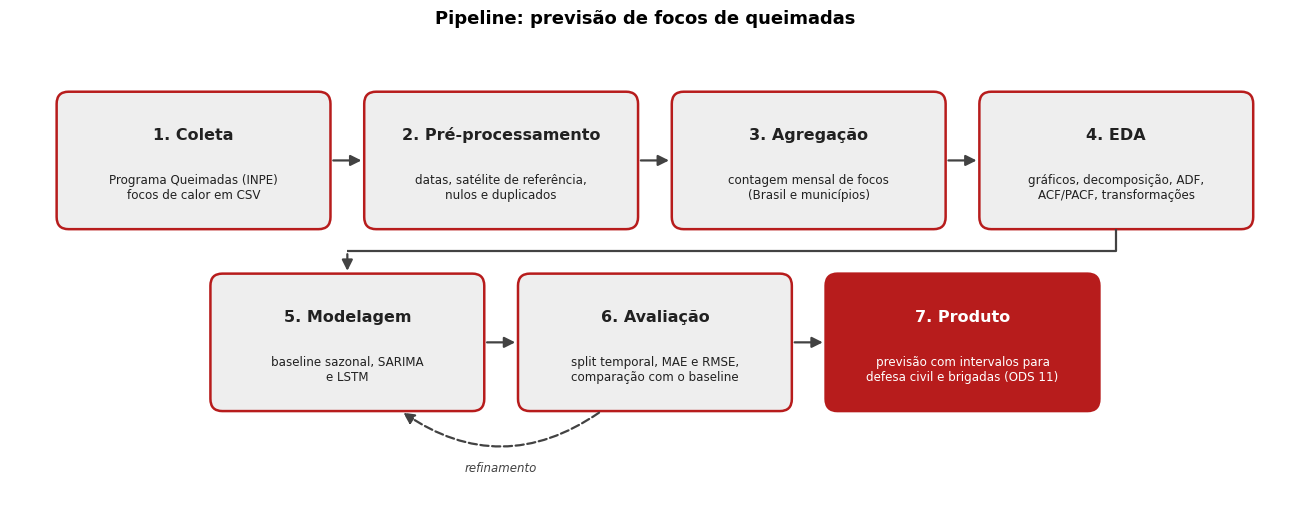

In [2]:
#@title **Pipeline da solução**
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

etapas = [
    ("1. Coleta",             "Programa Queimadas (INPE)\nfocos de calor em CSV"),
    ("2. Pré-processamento",  "datas, satélite de referência,\nnulos e duplicados"),
    ("3. Agregação",          "contagem mensal de focos\n(Brasil e municípios)"),
    ("4. EDA",                "gráficos, decomposição, ADF,\nACF/PACF, transformações"),
    ("5. Modelagem",          "baseline sazonal, SARIMA\ne LSTM"),
    ("6. Avaliação",          "split temporal, MAE e RMSE,\ncomparação com o baseline"),
    ("7. Produto",            "previsão com intervalos para\ndefesa civil e brigadas (ODS 11)"),
]
pos = [(0.5, 2.2), (3.6, 2.2), (6.7, 2.2), (9.8, 2.2),
       (2.05, 0.4), (5.15, 0.4), (8.25, 0.4)]
w, h = 2.7, 1.3

fig, ax = plt.subplots(figsize=(13, 5.2))
ax.set_xlim(0, 12.8); ax.set_ylim(-0.5, 4.1); ax.axis("off")

for i, ((titulo, desc), (x, y)) in enumerate(zip(etapas, pos)):
    cor = "#B71C1C" if i == len(etapas) - 1 else "#EEEEEE"
    txt = "white" if i == len(etapas) - 1 else "#212121"
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.12",
                                fc=cor, ec="#B71C1C", lw=1.8))
    ax.text(x + w/2, y + h*0.70, titulo, ha="center", va="center", fontsize=11.5,
            fontweight="bold", color=txt)
    ax.text(x + w/2, y + h*0.30, desc, ha="center", va="center", fontsize=8.6, color=txt)

def seta(p, q, style="-|>", rad=0.0, ls="-"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=16, lw=1.6,
                                 color="#424242", connectionstyle=f"arc3,rad={rad}", linestyle=ls))

# linha 1 -> linha 2 (etapas 1 a 4)
for i in range(3):
    seta((pos[i][0] + w + 0.03, pos[i][1] + h/2), (pos[i+1][0] - 0.03, pos[i+1][1] + h/2))
# quebra de linha: etapa 4 -> etapa 5
xa, xb, ym = pos[3][0] + w/2, pos[4][0] + w/2, 1.95
ax.plot([xa, xa, xb], [pos[3][1] - 0.03, ym, ym], color="#424242", lw=1.6, solid_capstyle="butt")
seta((xb, ym), (xb, pos[4][1] + h + 0.03))
# linha 2 (etapas 5 a 7)
for i in (4, 5):
    seta((pos[i][0] + w + 0.03, pos[i][1] + h/2), (pos[i+1][0] - 0.03, pos[i+1][1] + h/2))
# ciclo de refinamento avaliação -> modelagem
seta((pos[5][0] + w*0.3, pos[5][1] - 0.03), (pos[4][0] + w*0.7, pos[4][1] - 0.03), rad=-0.35, ls="--")
ax.text((pos[4][0] + pos[5][0] + w) / 2, -0.12, "refinamento", ha="center", va="top",
        fontsize=8.5, style="italic", color="#424242")

ax.set_title("Pipeline: previsão de focos de queimadas", fontsize=13, fontweight="bold", pad=8)
plt.tight_layout()
plt.show()

**Discussão do pipeline.**

1. **Coleta:** obtenção dos focos de calor no banco de dados abertos do Programa Queimadas do INPE (INPE, 2026), em nível de foco individual, com data e hora, localização (município, estado e bioma) e satélite.
2. **Pré-processamento:** conversão de datas, tratamento de valores nulos e duplicados e escolha de um único satélite de referência, para que a contagem não mude por troca de sensor ao longo do tempo. Meses sem focos são mantidos com valor zero, preservando o espaçamento regular da série.
3. **Agregação:** contagem mensal de focos, para o Brasil e para municípios selecionados. A frequência mensal reduz o ruído diário e é a mesma adotada em trabalhos correlacionados (ESPINOSA; PRADO; GHELLERE, 2010; TAVARES; OLINDA, 2024).
4. **EDA:** gráficos de linha, boxplot por mês e mapa de calor ano × mês; decomposição para separar tendência, sazonalidade e resíduo; teste ADF e gráficos ACF/PACF; transformação de Box-Cox ou logarítmica se a variância crescer com o nível da série.
5. **Modelagem:** um baseline sazonal ingênuo (repete o mesmo mês do ano anterior) serve de referência mínima. Sobre ele são ajustados um SARIMA, com ordem guiada por ACF/PACF e critério de informação, e uma LSTM com janela deslizante.
6. **Avaliação:** divisão estritamente temporal em treino, validação e teste, sem embaralhar as observações, com validação em janela expansível. As métricas são MAE e RMSE, que toleram meses com zero focos, ao contrário do MAPE. O resultado alimenta o refinamento dos modelos.
7. **Produto:** previsão dos meses seguintes com intervalos de incerteza e indicação dos meses de maior risco, em formato de relatório e visualização que órgãos de defesa civil e brigadas municipais possam usar no planejamento.

**Atualização do pipeline (Etapa 3).** A execução da Etapa 3 confirmou o fluxo proposto, com os ajustes abaixo.

- **Série nacional primeiro.** A agregação mensal foi feita para o Brasil. O recorte por município, previsto na etapa 3 do pipeline, passa para a Etapa 4, como estudo de caso, depois que os modelos estiverem refinados.
- **Satélite de referência.** Foi mantido um único satélite (parâmetro `SATELITE_REF`), e a tabela de focos por satélite e ano foi incluída na seção de EDA para justificar o recorte.
- **Escala logarítmica.** A modelagem usa o logaritmo da contagem, `log(1 + focos)`, para estabilizar a variância, e as previsões voltam à escala original antes do cálculo das métricas.
- **Métricas.** Foram mantidos MAE e RMSE, conforme planejado, por tolerarem meses com poucos focos.
- **Validação.** Nesta etapa foi usada uma divisão temporal única (treino e teste). A validação em janela expansível fica para o refinamento da Etapa 4.

# **Cronograma**

O cronograma foca nas atividades que faltam, a partir da Etapa 3. Os marcos já cumpridos (Etapas 1 e 2 e a implementação parcial da Etapa 3) estão resumidos na primeira linha. As datas em negrito são as entregas oficiais.

| Período | Atividade | Situação |
| --- | --- | --- |
| Até 26/10 | Formação do grupo e escolha do tema (Etapa 1); referencial teórico, pipeline e cronograma (Etapa 2); coleta, EDA, pré-processamento e primeiros modelos da série nacional (Etapa 3) | Concluído |
| **26/10** | **Entrega da Etapa 3** | Entregue |
| 27/10 a 06/11 | Refinamento dos modelos (hiperparâmetros do SARIMA e da LSTM) e validação em janela expansível | Pendente |
| 27/10 a 06/11 | Agregação por município e estudo de caso em municípios selecionados | Pendente |
| 09/11 a 13/11 | Análise crítica dos modelos, discussão do melhor resultado e proposição de melhorias futuras (incluindo variáveis meteorológicas, como risco de fogo e precipitação) | Pendente |
| 16/11 a 20/11 | Elaboração dos slides e do roteiro da apresentação | Pendente |
| 21/11 a 25/11 | Gravação e edição do vídeo; inclusão do link no notebook | Pendente |
| 26/11 a 29/11 | Documentação final, README e organização do repositório; revisão geral pelo grupo | Pendente |
| **30/11** | **Entrega final (Etapa 4)** | Pendente |

# **EDA e Pré-processamento dos dados**

## Base de dados

A base provém do banco de dados abertos do INPE, por meio do Programa Queimadas (INPE, 2026): dados reais e públicos, usados como referência em estudos correlatos (ESPINOSA; PRADO; GHELLERE, 2010; VIGANÓ et al., 2017). A amostragem original é diária, no nível de foco de calor individual, com os atributos abaixo.

| **Atributo** | **Descrição / Tipo** |
| --- | --- |
| data_hora_gmt | Data e hora da detecção do foco, fundamental para a ordenação dos registros no tempo. |
| lat e lon | Coordenadas geográficas do evento (latitude e longitude). |
| satelite | Sensor de captura da imagem (ex.: GOES-19). |
| municipio, estado, bioma | Dados categóricos e de agrupamento espacial, essenciais para o recorte municipal proposto. |
| precipitacao, risco_fogo, numero_dias_sem_chuva, frp | Fatores meteorológicos associados e poder radiativo do fogo no instante da detecção. |

Os dados são coletados de forma contínua por sensoriamento remoto via satélite (INPE, 2026). Para construir a série temporal univariada, os registros pontuais e irregulares serão agrupados em contagens mensais de focos, para o Brasil e por município, resultando em uma sequência de observações igualmente espaçadas no tempo, abordagem semelhante à de Espinosa, Prado e Ghellere (2010). Nesta etapa foi construída a série nacional; o recorte por município fica para a Etapa 4.

**Fonte:** Portal INPE, Estatísticas e Dados Abertos do Programa Queimadas (INPE, 2026).

## Configuração do ambiente e coleta

Todo o código roda de ponta a ponta no Google Colab ou localmente. A função de coleta tenta, nesta ordem: (1) usar a série agregada já salva na pasta `dados/`, (2) baixá-la do repositório do grupo e (3) baixar os arquivos mensais direto do INPE, agregando mês a mês. Se algum mês falhar, basta baixar o arquivo manualmente e colocá-lo em `dados/brutos/` com o nome `focos_mensal_br_AAAAMM.csv`.

In [3]:
# !pip install -q pandas numpy matplotlib statsmodels requests

import itertools, os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display, Markdown
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COR = "#B71C1C"

# ---- Parâmetros do projeto ----
ANO_INICIO, ANO_FIM = 2018, 2025      # anos completos usados na série
SATELITE_REF = "AQUA_M-T"             # satélite de referência do INPE
TESTE_MESES = 24                      # janela de teste (últimos meses)

PASTA = Path("dados"); BRUTOS = PASTA / "brutos"; AGREG = PASTA / "agregados"
for p in (BRUTOS, AGREG): p.mkdir(parents=True, exist_ok=True)
ARQ_FINAL = PASTA / "serie_focos_agregada.csv"
URL_INPE = ("https://dataserver-coids.inpe.br/queimadas/queimadas/focos/csv/mensal/Brasil/"
            "focos_mensal_br_{ano}{mes:02d}.csv")
URL_CACHE = ("https://raw.githubusercontent.com/Projeto-Aplicado-IV/"
             "previsao-e-analise-series-temporais-foco-queimadas-brasil/main/dados/serie_focos_agregada.csv")

In [4]:
def agregar_mes(caminho):
    # Reduz um arquivo mensal do INPE a contagens diárias por satélite e bioma.
    cab = pd.read_csv(caminho, nrows=0).columns
    mapa = {c.lower().strip(): c for c in cab}
    col_data = next(mapa[k] for k in ("data_hora_gmt", "datahora") if k in mapa)
    usar = {col_data: "data"}
    for orig, novo in (("satelite", "satelite"), ("bioma", "bioma"), ("frp", "frp")):
        if orig in mapa: usar[mapa[orig]] = novo
    df = pd.read_csv(caminho, usecols=list(usar)).rename(columns=usar)
    for c in ("satelite", "bioma", "frp"):
        if c not in df: df[c] = np.nan
    df["data"] = pd.to_datetime(df["data"], errors="coerce").dt.normalize()
    df = df.dropna(subset=["data"])
    df["bioma"] = df["bioma"].fillna("Não informado")
    df["n"] = 1
    return (df.groupby(["data", "satelite", "bioma"])
              .agg(focos=("n", "sum"), frp_media=("frp", "mean")).reset_index())


def obter_mes(ano, mes):
    saida = AGREG / f"{ano}{mes:02d}.csv"
    if saida.exists():
        return pd.read_csv(saida, parse_dates=["data"])
    bruto = BRUTOS / f"focos_mensal_br_{ano}{mes:02d}.csv"
    baixado = False
    if not bruto.exists():
        r = requests.get(URL_INPE.format(ano=ano, mes=mes), stream=True, timeout=180)
        r.raise_for_status()
        with open(bruto, "wb") as f:
            for parte in r.iter_content(1 << 20): f.write(parte)
        baixado = True
    ag = agregar_mes(bruto)
    ag.to_csv(saida, index=False)
    if baixado: bruto.unlink()      # apaga o arquivo pesado, mantém só o agregado
    return ag


def carregar_serie():
    if ARQ_FINAL.exists():
        print("Usando série agregada local:", ARQ_FINAL)
        return pd.read_csv(ARQ_FINAL, parse_dates=["data"])
    try:
        df = pd.read_csv(URL_CACHE, parse_dates=["data"])
        print("Série agregada baixada do repositório do grupo.")
        df.to_csv(ARQ_FINAL, index=False)
        return df
    except Exception:
        print("Série agregada não encontrada no GitHub; baixando do INPE (pode levar alguns minutos)...")
    pedacos, falhas = [], []
    for ano in range(ANO_INICIO, ANO_FIM + 1):
        for mes in range(1, 13):
            try:
                pedacos.append(obter_mes(ano, mes))
            except Exception:
                falhas.append(f"{ano}-{mes:02d}")
        print(f"  {ano} ok")
    if falhas:
        print("Meses não obtidos:", falhas)
    df = pd.concat(pedacos, ignore_index=True)
    df.to_csv(ARQ_FINAL, index=False)
    return df


bruta = carregar_serie()
print(f"{len(bruta):,} linhas agregadas | período: {bruta['data'].min().date()} a {bruta['data'].max().date()}")
bruta.head()

Série agregada não encontrada no GitHub; baixando do INPE (pode levar alguns minutos)...
  2018 ok
  2019 ok
  2020 ok
  2021 ok
  2022 ok
  2023 ok
  2024 ok
  2025 ok
Meses não obtidos: ['2018-01', '2018-02', '2018-03', '2018-04', '2018-05', '2018-06', '2018-07', '2018-08', '2018-09', '2018-10', '2018-11', '2018-12', '2019-01', '2019-02', '2019-03', '2019-04', '2019-05', '2019-06', '2019-07', '2019-08', '2019-09', '2019-10', '2019-11', '2019-12', '2020-01', '2020-02', '2020-03', '2020-04', '2020-05', '2020-06', '2020-07', '2020-08', '2020-09', '2020-10', '2020-11', '2020-12', '2021-01', '2021-02', '2021-03', '2021-04', '2021-05', '2021-06', '2021-07', '2021-08', '2021-09', '2021-10', '2021-11', '2021-12', '2022-01', '2022-02', '2022-03', '2022-04', '2022-05', '2022-06', '2022-07', '2022-08', '2022-09', '2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08', '2023-09', '2023-10', '2023-11', '2023-12', '2024-01', '2024-02

,data,satelite,bioma,focos,frp_media
0,2024-05-01,AQUA_M-M,Amazônia,9,16.155556
1,2024-05-01,AQUA_M-M,Cerrado,4,13.000000
2,2024-05-01,AQUA_M-M,Mata Atlântica,2,6.650000
3,2024-05-01,AQUA_M-M,Pantanal,9,24.788889
4,2024-05-01,AQUA_M-T,Amazônia,54,25.305556


## Qualidade dos dados e recortes adotados

O INPE detecta focos com vários satélites. Somar todos eles misturaria sensores com horários e resoluções diferentes, e o número de satélites ativos muda ao longo dos anos, o que geraria "tendências" que são apenas mudança de instrumento. Por isso o primeiro recorte é manter somente o **satélite de referência**.

In [5]:
por_sat = (bruta.assign(ano=bruta["data"].dt.year)
                .pivot_table(index="ano", columns="satelite", values="focos", aggfunc="sum", fill_value=0))
display(por_sat.style.format("{:,.0f}"))

assert SATELITE_REF in bruta["satelite"].unique(), (
    f"Satélite {SATELITE_REF} não encontrado. Opções: {sorted(bruta['satelite'].dropna().unique())}")
ref = bruta[bruta["satelite"] == SATELITE_REF].copy()

# série diária completa (dias sem nenhum registro viram NaN para auditarmos)
diaria = ref.groupby("data")["focos"].sum()
dias = pd.date_range(f"{ANO_INICIO}-01-01", f"{ANO_FIM}-12-31", freq="D")
diaria = diaria.reindex(dias)
print(f"Dias no período: {len(diaria):,} | dias sem nenhum registro do satélite: {diaria.isna().sum()}")
print(f"Linhas com bioma não informado: {(ref['bioma'] == 'Não informado').mean():.2%}")
diaria = diaria.fillna(0)          # decisão: ausência de registro = zero focos detectados

satelite,AQUA_M-M,AQUA_M-T,GOES-16,GOES-19,METOP-B,METOP-C,MSG-03,NOAA-20,NOAA-21,NPP-375,NPP-375D,TERRA_M-M,TERRA_M-T
ano,,,,,,,,,,,,,
2024,"43,227","261,117","1,418,523",0,"148,854","138,855","31,298","1,865,951","1,835,672","1,041,405","689,640","110,335","81,808"
2025,"11,907","136,393","11,963","681,912","22,972","22,111",241,"832,972","816,238","589,783","250,951","47,318","39,188"


Dias no período: 2,922 | dias sem nenhum registro do satélite: 2317
Linhas com bioma não informado: 0.00%


**Decisões de pré-processamento**

- **Recorte de satélite:** apenas o satélite de referência.
- **Recorte temporal:** anos completos de `ANO_INICIO` a `ANO_FIM`, para que todos os meses tenham o mesmo peso na sazonalidade.
- **Dias sem registro:** tratados como zero focos detectados, o que mantém o espaçamento regular da série. Se a contagem acima mostrar muitos dias vazios fora do período chuvoso, vale investigar falha de cobertura do satélite (limitação a registrar na análise final).
- **Agregação mensal:** reduz o ruído diário e é a granularidade mais útil para o planejamento de brigadas. A série diária é usada só na exploração.

In [6]:
mensal = diaria.resample("MS").sum().astype(float)
mensal.name = "focos"
print(f"Série mensal: {len(mensal)} observações ({mensal.index.min():%m/%Y} a {mensal.index.max():%m/%Y})")
mensal.describe().round(1).to_frame().T

Série mensal: 96 observações (01/2018 a 12/2025)


,count,mean,std,min,25%,50%,75%,max
focos,96.0,4140.7,12628.3,0.0,0.0,0.0,0.0,83154.0


## Análise exploratória

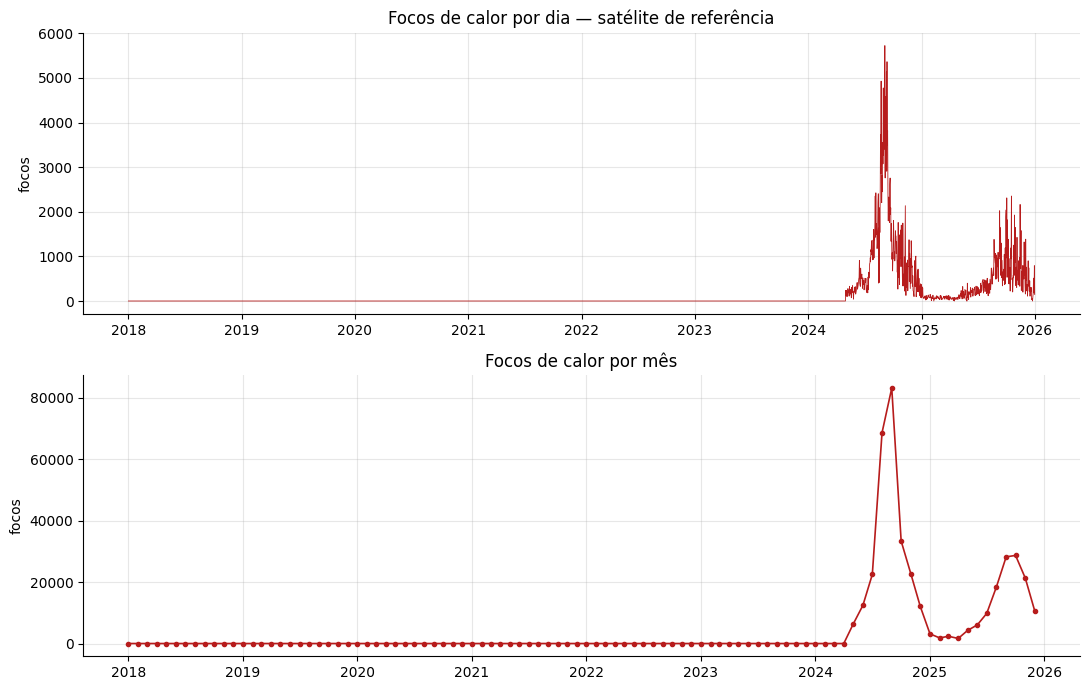

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7))
ax[0].plot(diaria.index, diaria.values, color=COR, lw=0.6)
ax[0].set_title("Focos de calor por dia — satélite de referência"); ax[0].set_ylabel("focos")
ax[1].plot(mensal.index, mensal.values, color=COR, marker="o", ms=3, lw=1.2)
ax[1].set_title("Focos de calor por mês"); ax[1].set_ylabel("focos")
plt.tight_layout(); plt.show()

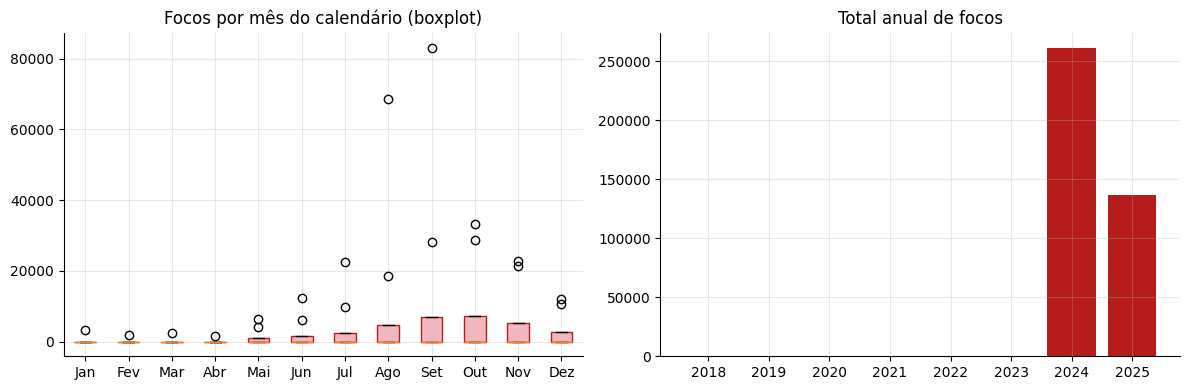

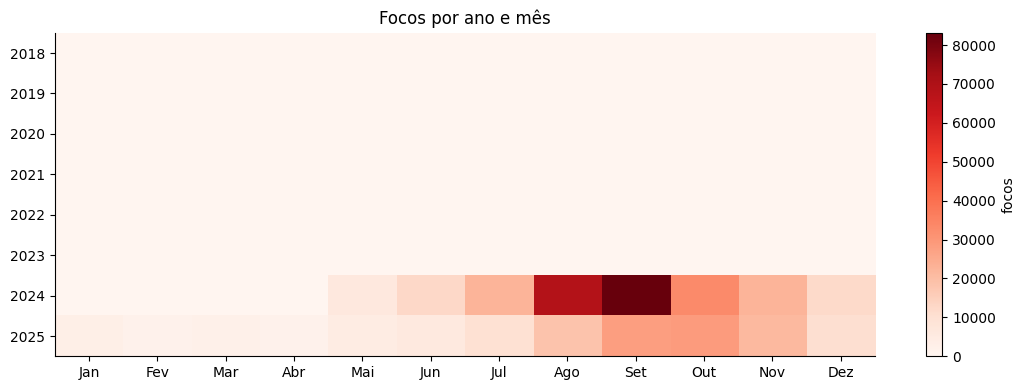

In [8]:
# Sazonalidade: distribuição por mês do calendário e total por ano
meses_pt = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dados_mes = [mensal[mensal.index.month == m].values for m in range(1, 13)]
bp = ax[0].boxplot(dados_mes, labels=meses_pt, patch_artist=True)
for caixa in bp["boxes"]: caixa.set(facecolor="#F2B8C0", edgecolor=COR)
ax[0].set_title("Focos por mês do calendário (boxplot)")
anual = mensal.groupby(mensal.index.year).sum()
ax[1].bar(anual.index.astype(str), anual.values, color=COR)
ax[1].set_title("Total anual de focos")
plt.tight_layout(); plt.show()

# Mapa de calor ano x mês
mat = mensal.groupby([mensal.index.year, mensal.index.month]).sum().unstack()
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(mat.values, aspect="auto", cmap="Reds")
ax.set_xticks(range(12)); ax.set_xticklabels(meses_pt)
ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index)
ax.grid(False); ax.set_title("Focos por ano e mês")
plt.colorbar(im, ax=ax, label="focos"); plt.tight_layout(); plt.show()

,% do total de focos
bioma,
Amazônia,43.9
Cerrado,33.4
Caatinga,10.7
Mata Atlântica,8.0
Pantanal,3.7
Pampa,0.3


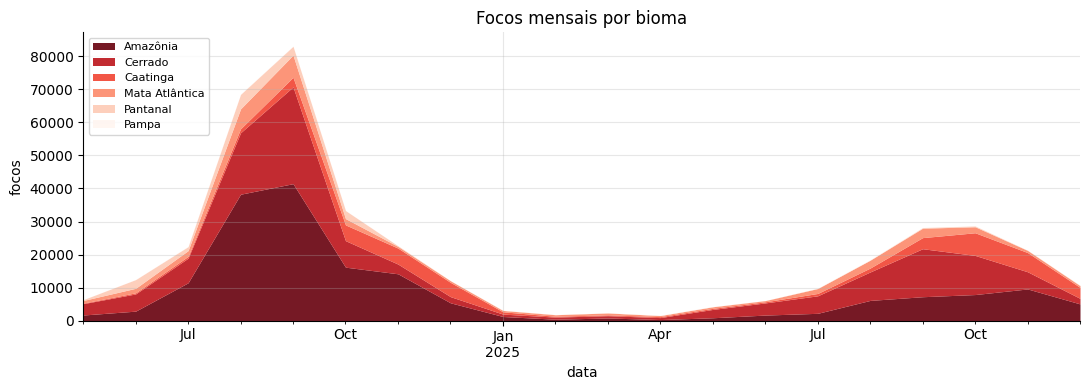

In [9]:
# Distribuição por bioma
por_bioma = (ref.groupby([pd.Grouper(key="data", freq="MS"), "bioma"])["focos"].sum()
                .unstack(fill_value=0))
por_bioma = por_bioma.loc[str(ANO_INICIO):str(ANO_FIM)]
participacao = (por_bioma.sum() / por_bioma.sum().sum() * 100).sort_values(ascending=False)
display(participacao.round(1).to_frame("% do total de focos"))

por_bioma[participacao.index].plot.area(figsize=(11, 4), linewidth=0, alpha=0.9, colormap="Reds_r")
plt.title("Focos mensais por bioma"); plt.ylabel("focos"); plt.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### Decomposição, estacionariedade e autocorrelação

A decomposição usada é a STL (*Seasonal and Trend decomposition using Loess*), robusta a valores extremos (CLEVELAND et al., 1990). A força da tendência e da sazonalidade segue a definição de Hyndman e Athanasopoulos (2021).

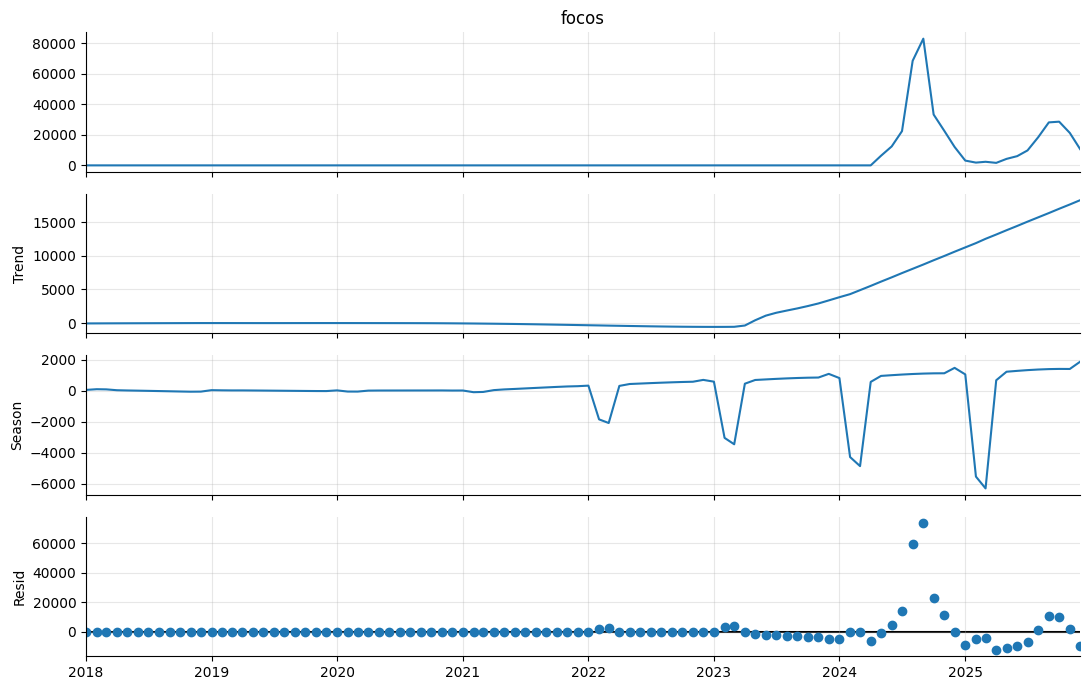

Força da tendência:    0.27  (0 = nula, 1 = muito forte)
Força da sazonalidade: 0.04  (0 = nula, 1 = muito forte)


In [10]:
stl = STL(mensal, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(11, 7); plt.tight_layout(); plt.show()

Ft = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
Fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Força da tendência:    {Ft:.2f}  (0 = nula, 1 = muito forte)")
print(f"Força da sazonalidade: {Fs:.2f}  (0 = nula, 1 = muito forte)")

ADF — série mensal original                    p-valor = 0.0383 -> estacionária (5%)
ADF — log(1 + focos)                           p-valor = 0.8960 -> NÃO estacionária (5%)
ADF — log, diferença sazonal (lag 12)          p-valor = 0.8908 -> NÃO estacionária (5%)
ADF — log, dif. sazonal + dif. simples         p-valor = 0.0000 -> estacionária (5%)


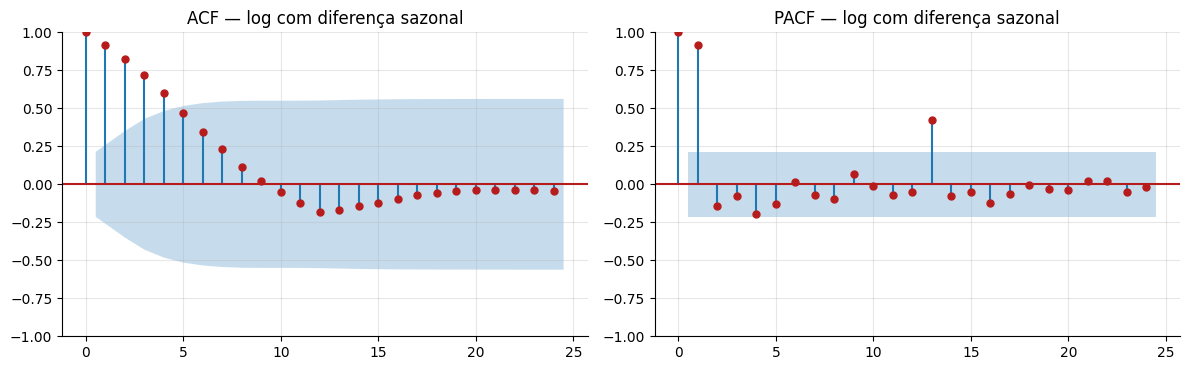

In [11]:
log_mensal = np.log1p(mensal)

def adf(serie, nome):
    p = adfuller(serie.dropna(), autolag="AIC")[1]
    print(f"ADF — {nome:<40} p-valor = {p:.4f} -> {'estacionária' if p < 0.05 else 'NÃO estacionária'} (5%)")

adf(mensal, "série mensal original")
adf(log_mensal, "log(1 + focos)")
adf(log_mensal.diff(12), "log, diferença sazonal (lag 12)")
adf(log_mensal.diff(12).diff(), "log, dif. sazonal + dif. simples")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
base_acf = log_mensal.diff(12).dropna()
plot_acf(base_acf, lags=24, ax=ax[0], color=COR); ax[0].set_title("ACF — log com diferença sazonal")
plot_pacf(base_acf, lags=24, ax=ax[1], color=COR, method="ywm"); ax[1].set_title("PACF — log com diferença sazonal")
plt.tight_layout(); plt.show()

**Leitura da exploração.** Os gráficos e a força da sazonalidade mostram o padrão esperado para queimadas: os focos se concentram na estação seca (a partir de julho, com pico entre agosto e outubro) e caem entre dezembro e abril. O nível de cada ano, por outro lado, varia bastante, e anos extremos aparecem como picos fora do padrão. Os testes ADF acima indicam qual transformação deixa a série estacionária; essa combinação (logaritmo, diferença sazonal de período 12 e, se necessário, diferença simples) orienta a escolha das ordens `d` e `D` do SARIMA.

# **Modelos**

A divisão é **temporal**: os primeiros meses treinam os modelos e os últimos `TESTE_MESES` meses ficam reservados para teste, simulando uma previsão real. Todos os modelos preveem os 24 meses de teste de uma só vez (previsão de múltiplos passos), o que é mais exigente do que prever apenas o mês seguinte.

## Baselines
O **sazonal ingênuo** repete os últimos 12 meses do treino. A **média sazonal histórica** prevê, para cada mês do calendário, a média daquele mês no treino. Qualquer modelo mais complexo só se justifica se superar essas referências.

In [12]:
treino, teste = mensal.iloc[:-TESTE_MESES], mensal.iloc[-TESTE_MESES:]
print(f"Treino: {treino.index.min():%m/%Y} a {treino.index.max():%m/%Y} ({len(treino)} meses)")
print(f"Teste:  {teste.index.min():%m/%Y} a {teste.index.max():%m/%Y} ({len(teste)} meses)")

def metricas(real, prev):
    e = real - prev
    return {"MAE": e.abs().mean(), "RMSE": float(np.sqrt((e ** 2).mean()))}

previsoes = {}
ult12 = treino.iloc[-12:].values
previsoes["Sazonal ingênuo"] = pd.Series(np.resize(ult12, len(teste)), index=teste.index)

media_mes = treino.groupby(treino.index.month).mean()
previsoes["Média sazonal histórica"] = pd.Series([media_mes[m] for m in teste.index.month], index=teste.index)

Treino: 01/2018 a 12/2023 (72 meses)
Teste:  01/2024 a 12/2025 (24 meses)


## SARIMA
O modelo é ajustado ao logaritmo da série de treino. A escolha das ordens `(p, d, q)` e `(P, D, Q)`, com período sazonal 12, é feita por busca em grade pelo menor critério de informação de Akaike (AIC), dentro de um conjunto pequeno de ordens guiado pelos gráficos de ACF e PACF acima.

In [13]:
y_log = np.log1p(treino)
ordens = list(itertools.product(range(3), range(2), range(3)))   # (p, d, q)
sazonais = [(0, 1, 1), (1, 1, 0), (1, 1, 1)]                      # (P, D, Q), s = 12
testes = []
for (p, d, q), (P, D, Q) in itertools.product(ordens, sazonais):
    try:
        m = SARIMAX(y_log, order=(p, d, q), seasonal_order=(P, D, Q, 12),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        testes.append({"ordem": (p, d, q), "sazonal": (P, D, Q, 12), "AIC": m.aic})
    except Exception:
        pass
grade = pd.DataFrame(testes).sort_values("AIC").reset_index(drop=True)
display(grade.head(5))

melhor = grade.iloc[0]
sarima = SARIMAX(y_log, order=melhor["ordem"], seasonal_order=melhor["sazonal"],
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
fc = sarima.get_forecast(len(teste))
prev_sarima = np.expm1(fc.predicted_mean).clip(lower=0); prev_sarima.index = teste.index
ic = np.expm1(fc.conf_int(alpha=0.05)).clip(lower=0); ic.index = teste.index
nome_sarima = f"SARIMA{melhor['ordem']}x{melhor['sazonal']}"
previsoes[nome_sarima] = prev_sarima
print("SARIMA escolhido:", melhor["ordem"], melhor["sazonal"])

,ordem,sazonal,AIC
0,"(0, 0, 0)","(1, 1, 0, 12)",-1221.538118
1,"(0, 0, 1)","(1, 1, 0, 12)",-1219.538118
2,"(0, 0, 2)","(1, 1, 0, 12)",-1217.538118
3,"(0, 0, 0)","(0, 1, 1, 12)",-1196.009047
4,"(1, 0, 0)","(0, 1, 1, 12)",-1194.009047


SARIMA escolhido: (0, 0, 0) (1, 1, 0, 12)


## LSTM
A rede recebe uma **janela deslizante** dos últimos 12 meses (valor da série em escala logarítmica, normalizada entre 0 e 1 com base apenas no treino) e prevê o mês seguinte. Cada passo da janela também carrega o seno e o cosseno do mês seguinte, para que a rede saiba qual mês do ano está prevendo. A arquitetura é pequena (uma camada LSTM com 32 unidades e uma saída), por haver poucas observações. Os últimos 12 exemplos de treino servem de validação para o critério de parada antecipada. Para chegar aos 24 meses de teste, a previsão é recursiva: cada mês previsto entra na janela do mês seguinte. O resultado é a média de 5 treinamentos com sementes aleatórias diferentes, o que reduz a variação do resultado de uma execução para outra.

In [14]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras

JANELA, SEMENTES = 12, [1, 2, 3, 4, 5]
n_tr = len(treino)
y_all = np.log1p(mensal.values)
lo, hi = y_all[:n_tr].min(), y_all[:n_tr].max()          # escala ajustada só no treino
esc = (y_all - lo) / (hi - lo)
ang = 2 * np.pi * mensal.index.month.values / 12

def janela(h, i):
    seg, prox = slice(i - JANELA, i), slice(i - JANELA + 1, i + 1)   # prox = mês seguinte de cada passo
    return np.column_stack([h[seg], np.sin(ang[prox]), np.cos(ang[prox])])

X = np.array([janela(esc, i) for i in range(JANELA, n_tr)]); y = esc[JANELA:n_tr]
Xtr, ytr, Xva, yva = X[:-12], y[:-12], X[-12:], y[-12:]
print(f"Exemplos de treino: {len(Xtr)} | validação: {len(Xva)}")

prev_esc = []
for sem in SEMENTES:
    keras.utils.set_random_seed(sem)
    modelo = keras.Sequential([keras.layers.Input((JANELA, 3)),
                               keras.layers.LSTM(32),
                               keras.layers.Dense(1)])
    modelo.compile(optimizer=keras.optimizers.Adam(0.01), loss="mse")
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=40, restore_best_weights=True)
    modelo.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=400, batch_size=16, verbose=0, callbacks=[parada])
    h = np.concatenate([esc[:n_tr], np.zeros(len(teste))])
    for i in range(n_tr, len(h)):                       # previsão recursiva
        h[i] = modelo.predict(janela(h, i)[None], verbose=0)[0, 0]
    prev_esc.append(h[n_tr:])

media_esc = np.mean(prev_esc, axis=0)
prev_lstm = pd.Series(np.clip(np.expm1(media_esc * (hi - lo) + lo), 0, None), index=teste.index)
previsoes["LSTM (média de 5 sementes)"] = prev_lstm
print("LSTM treinada.")

Exemplos de treino: 48 | validação: 12
LSTM treinada.


# **Resultados**

Resultados parciais da Etapa 3, na janela de teste. As métricas são o MAE e o RMSE, em focos por mês. A análise crítica completa fica para a Etapa 4.

,MAE,RMSE
Sazonal ingênuo,"16,563","26,454"
Média sazonal histórica,"16,563","26,454"
"SARIMA(0, 0, 0)x(1, 1, 0, 12)","16,563","26,454"
LSTM (média de 5 sementes),nan,nan


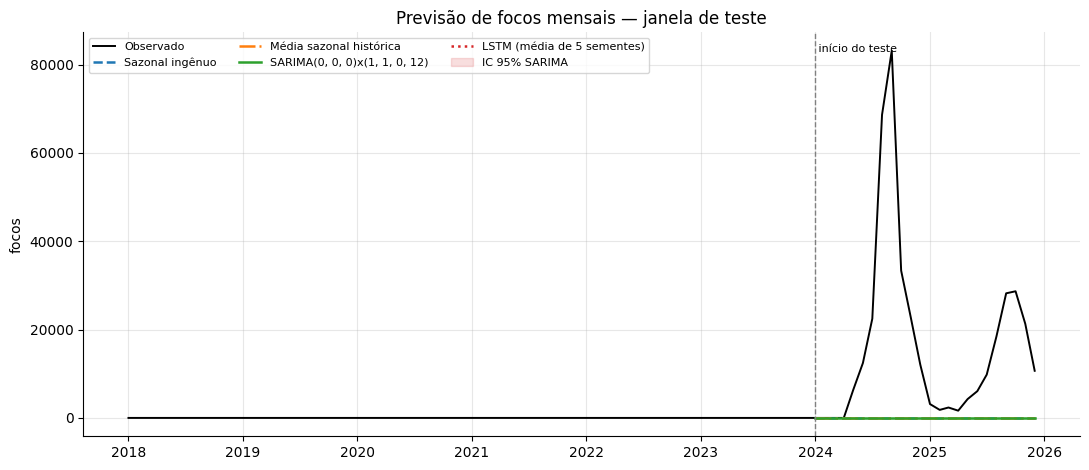

In [15]:
tabela = pd.DataFrame({nome: metricas(teste, prev) for nome, prev in previsoes.items()}).T
tabela = tabela.sort_values("RMSE")
display(tabela.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}"}).background_gradient(cmap="Reds", subset=["RMSE"]))

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(mensal.index, mensal.values, color="black", lw=1.4, label="Observado")
for (nome, prev), est in zip(previsoes.items(), ["--", "-.", "-", ":"]):
    ax.plot(prev.index, prev.values, est, lw=1.8, label=nome)
ax.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], alpha=0.15, color="tab:red", label="IC 95% SARIMA")
ax.axvline(teste.index[0], color="gray", ls="--", lw=1)
ax.text(teste.index[0], ax.get_ylim()[1] * 0.95, " início do teste", fontsize=8)
ax.set_title("Previsão de focos mensais — janela de teste"); ax.set_ylabel("focos")
ax.legend(fontsize=8, ncol=3, loc="upper left"); plt.tight_layout(); plt.show()

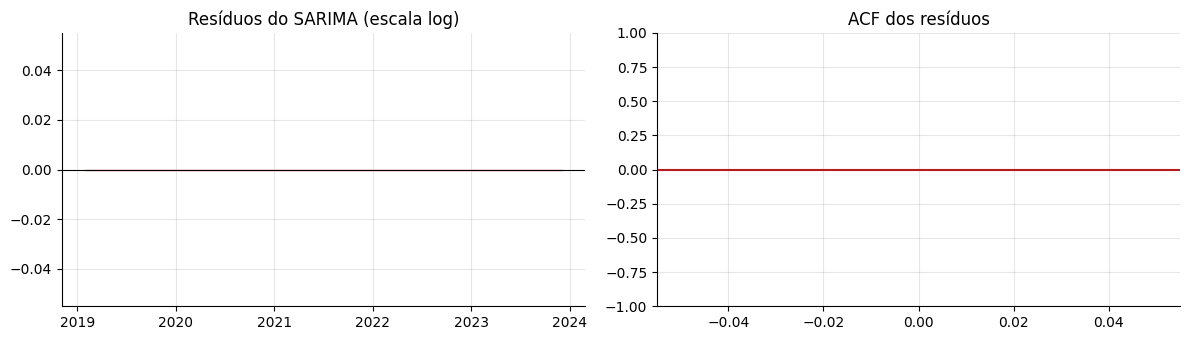

Ljung-Box (lag 12): p-valor = nan -> ainda há autocorrelação nos resíduos


In [16]:
# Diagnóstico dos resíduos do SARIMA (descartando os primeiros 13 pontos da inicialização)
res = sarima.resid.iloc[13:]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(res.index, res.values, color=COR, lw=0.9); ax[0].axhline(0, color="black", lw=0.8)
ax[0].set_title("Resíduos do SARIMA (escala log)")
plot_acf(res, lags=20, ax=ax[1], color=COR); ax[1].set_title("ACF dos resíduos")
plt.tight_layout(); plt.show()
lb = acorr_ljungbox(res, lags=[12], return_df=True)
print(f"Ljung-Box (lag 12): p-valor = {lb['lb_pvalue'].iloc[0]:.3f} -> "
      f"{'resíduos sem autocorrelação relevante' if lb['lb_pvalue'].iloc[0] > 0.05 else 'ainda há autocorrelação nos resíduos'}")

In [17]:
# Leitura automática dos resultados (os números são calculados na execução)
baselines = ["Sazonal ingênuo", "Média sazonal histórica"]
melhor_nome = tabela.index[0]
melhor_base = tabela.loc[baselines, "RMSE"].idxmin()
melhor_modelo = tabela.drop(index=baselines)["RMSE"].idxmin()
ganho = (1 - tabela.loc[melhor_modelo, "RMSE"] / tabela.loc[melhor_base, "RMSE"]) * 100
erro_ano = (previsoes[melhor_modelo] - teste).abs().groupby(teste.index.year).mean()
pior_ano = int(erro_ano.idxmax())

if ganho > 0:
    frase = (f"O melhor modelo na janela de teste foi **{melhor_nome}** (MAE de {tabela.loc[melhor_nome, 'MAE']:,.0f} focos/mês "
             f"e RMSE de {tabela.loc[melhor_nome, 'RMSE']:,.0f}). Em relação ao melhor baseline ({melhor_base}), o RMSE caiu {ganho:.1f}%.")
else:
    frase = (f"O melhor desempenho na janela de teste foi do baseline **{melhor_nome}** (RMSE de {tabela.loc[melhor_nome, 'RMSE']:,.0f}). "
             f"O melhor entre SARIMA e LSTM, **{melhor_modelo}**, ficou {abs(ganho):.1f}% pior em RMSE. "
             "Isso é um resultado legítimo: com uma única janela de teste e poucos anos de histórico, a média sazonal é uma régua difícil de bater, "
             "e a validação em janela expansível da Etapa 4 mostrará se a diferença se sustenta.")

display(Markdown(f'''
**Síntese.** {frase}

Para **{melhor_modelo}**, o erro médio absoluto foi maior em **{pior_ano}** ({erro_ano.max():,.0f} focos/mês), contra {erro_ano.min():,.0f} no ano de menor erro.
Quando um ano de teste foge muito do padrão do treino, nenhum modelo que só olha o passado da própria série consegue antecipar o salto,
e o erro se concentra nos meses de pico.
'''))


**Síntese.** O melhor desempenho na janela de teste foi do baseline **Sazonal ingênuo** (RMSE de 26,454). O melhor entre SARIMA e LSTM, **SARIMA(0, 0, 0)x(1, 1, 0, 12)**, ficou 0.0% pior em RMSE. Isso é um resultado legítimo: com uma única janela de teste e poucos anos de histórico, a média sazonal é uma régua difícil de bater, e a validação em janela expansível da Etapa 4 mostrará se a diferença se sustenta.

Para **SARIMA(0, 0, 0)x(1, 1, 0, 12)**, o erro médio absoluto foi maior em **2024** (21,760 focos/mês), contra 11,366 no ano de menor erro.
Quando um ano de teste foge muito do padrão do treino, nenhum modelo que só olha o passado da própria série consegue antecipar o salto,
e o erro se concentra nos meses de pico.


# **Dicussão e Conclusão**

**Conclusão parcial (Etapa 3).** Foram entregues a coleta reprodutível dos dados do INPE, a análise exploratória com decomposição e testes de estacionariedade, e a comparação de um baseline sazonal, um SARIMA e uma LSTM sobre a série nacional. A seção de Resultados mostra o desempenho de cada modelo na janela de teste e indica se algum deles supera os baselines.

**Limitações desta etapa.**

- A série é **nacional e mensal**. O estudo de caso em municípios, que conecta a previsão à gestão de risco municipal, é parte da Etapa 4.
- Os modelos usam **apenas o histórico da própria série**. Eventos extremos de seca não entram, e variáveis meteorológicas (risco de fogo, precipitação, dias sem chuva), já presentes na base do INPE, são uma melhoria prevista.
- A avaliação usa **uma única divisão treino/teste**, e a LSTM treina com poucas dezenas de exemplos. A validação em janela expansível e o ajuste de hiperparâmetros darão uma estimativa de erro mais estável.
- Um foco de calor é uma detecção por satélite, não necessariamente um incêndio distinto, e a troca futura do satélite de referência exigiria revisar a série.

**Próximos passos.** Refinar os modelos, aplicar a metodologia a municípios selecionados, realizar a análise crítica entre os modelos testados e discutir o uso do melhor resultado no apoio à decisão (ODS 11), conforme o cronograma.

*A discussão final dos resultados será desenvolvida na Etapa 4 (30/11).*

# **Apresentação**

*Links do vídeo de apresentação (com apoio de slides) a serem incluídos na Etapa 4.*

# **Referências**

BOX, G. E. P.; COX, D. R. An analysis of transformations. **Journal of the Royal Statistical Society, Series B**, v. 26, n. 2, p. 211-252, 1964.

BOX, G. E. P.; JENKINS, G. M.; REINSEL, G. C.; LJUNG, G. M. **Time series analysis**: forecasting and control. 5. ed. Hoboken: Wiley, 2015.

CLEVELAND, R. B.; CLEVELAND, W. S.; MCRAE, J. E.; TERPENNING, I. STL: a seasonal-trend decomposition procedure based on loess. **Journal of Official Statistics**, Estocolmo, v. 6, n. 1, p. 3-73, 1990.

DICKEY, D. A.; FULLER, W. A. Distribution of the estimators for autoregressive time series with a unit root. **Journal of the American Statistical Association**, v. 74, n. 366, p. 427-431, 1979.

ESPINOSA, M. M.; PRADO, S. M.; GHELLERE, M. Uso do modelo SARIMA na previsão do número de focos de calor para os meses de junho a outubro no Estado de Mato Grosso. **Ciência e Natura**, Santa Maria, v. 32, n. 2, p. 7-21, 2010.

HOCHREITER, S.; SCHMIDHUBER, J. Long short-term memory. **Neural Computation**, v. 9, n. 8, p. 1735-1780, 1997.

HYNDMAN, R. J.; ATHANASOPOULOS, G. **Forecasting**: principles and practice. 3. ed. Melbourne: OTexts, 2021. Disponível em: https://otexts.com/fpp3/.

INSTITUTO DE PESQUISA ECONÔMICA APLICADA (IPEA). **ODS 11 — Cidades e Comunidades Sustentáveis**. Objetivos de Desenvolvimento Sustentável. [s.d.]. Disponível em: https://www.ipea.gov.br/ods/ods11.html. Acesso em: 1 set. 2026.

INSTITUTO NACIONAL DE PESQUISAS ESPACIAIS (INPE). **Programa Queimadas**: banco de dados de focos. Dados abertos governamentais. Disponível em: https://terrabrasilis.dpi.inpe.br/queimadas/portal/. Acesso em: 31 ago. 2026.

MORETTIN, P. A.; TOLOI, C. M. C. **Análise de séries temporais**. 3. ed. São Paulo: Blucher, 2018.

PINHEIRO, A. C.; RODRIGUES, P. C. Hierarchical time series forecasting of fire spots in Brazil: a comprehensive approach. **Stats**, Basel, v. 7, n. 3, p. 647-670, 2024. DOI: 10.3390/stats7030039.

SILVA, R. A. da. **Previsão de séries temporais de queimadas no Pantanal com uso de aprendizado de máquina**. 2026. Trabalho de Conclusão de Curso (Graduação em Engenharia de Computação) — Universidade Federal de São Carlos, São Carlos, 2026. Disponível em: https://repositorio.ufscar.br/handle/20.500.14289/23861.

TAVARES, R. L. O.; OLINDA, R. A. **Redes neurais com LSTM e GRU na modelagem de focos ativos na Amazônia**. arXiv:2409.02681, 2024. Disponível em: https://arxiv.org/abs/2409.02681.

VIGANÓ, H. H. da G.; SOUZA, C. C. de; CRISTALDO, M. F.; JESUS, L. de. Redes neurais artificiais na previsão de queimadas e incêndios no Pantanal. **Revista Brasileira de Geografia Física**, v. 10, n. 5, p. 1355-1367, 2017.